# Netflix Recommendation Research Lab: Causal Uplift vs Preference Optimization

### Academic Viva & Oral Defense Edition
**Dataset**: MovieLens 1M (3,883 movies, 6,040 users, 1,000,209 ratings)  
**Primary Research Question**: Does optimizing recommendations for **causal uplift** (incremental watch probability) deliver greater business value than conventional **preference ranking** (predicted rating)?

---

### Core Concepts for Viva Defense
- **Preference-Based Recommendation**: Recommends items a user is predicted to rate highly (e.g., Matrix Factorization / SVD). A fundamental flaw is recommending *"Sure Things"*—blockbusters the user would have watched anyway without any intervention ($p_0 \approx 36\%$), wasting recommendation real estate.
- **Causal Uplift Recommendation**: Recommends items where showing the recommendation causes the largest *incremental increase* in watch probability:
  $$\tau(u, i) = \mathbb{E}[Y_1 - Y_0 \mid X_{u,i}]$$
  where $Y_1$ is the outcome if recommended, and $Y_0$ is the counterfactual organic outcome if withheld.
- **Two-Stage System Architecture**:
  1. *Candidate Generation (SVD)*: Efficiently filters the 3,883-movie catalog down to the top unrated candidates with high predicted user affinity.
  2. *Causal Reranking (X-Learner)*: Estimates individualized treatment effects (CATE) on candidate features and reranks them to maximize incremental impact.
- **Important Academic Limitation**: Real production recommendation telemetry is proprietary to streaming services. Therefore, this project implements a controlled, reproducible causal simulation grounded on real MovieLens 1M features to benchmark conventional models against causal algorithms.

In [1]:
# Cell 1: Data Ingestion, Cleaning & Basic Audit
# What we are doing: Loading raw MovieLens 1M files, cleaning titles/years, and verifying integrity.
# Why: Establishes a verified data foundation and guarantees zero corrupted or missing values.
# What to look for: Exact dataset dimensions (3,883 movies, 1,000,209 ratings, 6,040 users).

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from scipy.stats import pearsonr, spearmanr
from scipy.integrate import trapezoid

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_DIR = "D:/ADA_Netflix/Neflix-Recommendation"

# Load raw MovieLens 1M tables
movies_df = pd.read_csv(f"{DATA_DIR}/movies.dat", sep="::", engine="python", 
                        names=["MovieID", "Title", "Genres"], encoding="latin-1")
ratings_df = pd.read_csv(f"{DATA_DIR}/ratings.dat", sep="::", engine="python", 
                         names=["UserID", "MovieID", "Rating", "Timestamp"], encoding="latin-1")
users_df = pd.read_csv(f"{DATA_DIR}/users.dat", sep="::", engine="python", 
                       names=["UserID", "Gender", "Age", "Occupation", "ZipCode"], encoding="latin-1")

# Clean movie title, extract release year, and split genres
movies_df['ReleaseYear'] = movies_df['Title'].str.extract(r'\((\d{4})\)').astype(float).fillna(1990).astype(int)
movies_df['CleanTitle'] = movies_df['Title'].str.replace(r'\s*\(\d{4}\)', '', regex=True).str.strip()
movies_df['GenreList'] = movies_df['Genres'].str.split('|')
movies_df['GenreCount'] = movies_df['GenreList'].apply(len)

# Invariant assertions: Dataset dimensions and rating bounds
assert len(movies_df) == 3883, f"Expected 3,883 movies, found {len(movies_df)}"
assert len(ratings_df) == 1000209, f"Expected 1,000,209 ratings, found {len(ratings_df)}"
assert len(users_df) == 6040, f"Expected 6,040 users, found {len(users_df)}"
assert ratings_df['Rating'].between(1, 5).all(), "Ratings outside [1, 5] range"
assert ratings_df[['UserID', 'MovieID']].duplicated().sum() == 0, "Duplicate ratings detected"

print(f"Data Successfully Loaded & Audited:")
print(f"  - Movies  : {len(movies_df):,} catalog titles")
print(f"  - Ratings : {len(ratings_df):,} user-item interactions (Range: 1-5 stars)")
print(f"  - Users   : {len(users_df):,} distinct subscribers")

Data Successfully Loaded & Audited:
  - Movies  : 3,883 catalog titles
  - Ratings : 1,000,209 user-item interactions (Range: 1-5 stars)
  - Users   : 6,040 distinct subscribers


### Exploratory Data Analysis & Catalog Sparsity

**What are we doing?**  
Visualizing rating distributions, movie popularity concentration, and genre composition, and calculating interaction matrix sparsity.

**Why are we doing it?**  
Real-world recommendation systems suffer from severe interaction sparsity and long-tail popularity skew. Understanding these characteristics justifies why matrix factorization (SVD) and shrinkage methods (Bayesian prior) are required.

**Viva Metric Meaning**:
- **Matrix Sparsity (95.74%)**: Percentage of unobserved user-movie pairs. Shows that the average user has rated fewer than 5% of all movies in the catalog.

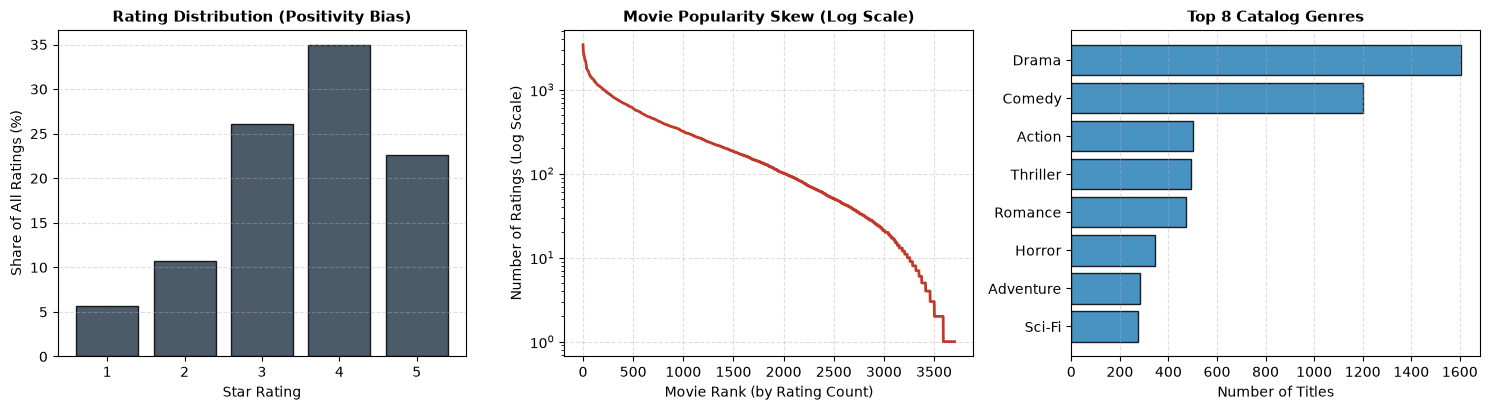

Matrix Sparsity: 95.74% | Global Mean Rating: 3.58 stars


In [2]:
# Cell 2: Exploratory Data Analysis & Sparsity
# What to look for: Positivity bias (most ratings are 3-5 stars) and extreme long-tail popularity skew.

n_users = users_df['UserID'].nunique()
n_movies = movies_df['MovieID'].nunique()
n_ratings = len(ratings_df)
sparsity = 1.0 - (n_ratings / (n_users * n_movies))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# 1. Rating Distribution (Positivity Bias)
rating_pct = ratings_df['Rating'].value_counts().sort_index() / n_ratings * 100
axes[0].bar(rating_pct.index, rating_pct.values, color='#2c3e50', edgecolor='black', alpha=0.85)
axes[0].set_title("Rating Distribution (Positivity Bias)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Star Rating")
axes[0].set_ylabel("Share of All Ratings (%)")
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# 2. Long-Tail Movie Popularity (Log-Linear)
movie_counts = ratings_df['MovieID'].value_counts().values
axes[1].plot(np.arange(len(movie_counts)), movie_counts, color='#c0392b', lw=2)
axes[1].set_yscale('log')
axes[1].set_title("Movie Popularity Skew (Log Scale)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Movie Rank (by Rating Count)")
axes[1].set_ylabel("Number of Ratings (Log Scale)")
axes[1].grid(True, linestyle='--', alpha=0.4)

# 3. Top Catalog Genres
all_genres = [g for sublist in movies_df['GenreList'] for g in sublist]
top_genres = pd.Series(all_genres).value_counts().head(8)
axes[2].barh(top_genres.index[::-1], top_genres.values[::-1], color='#2980b9', edgecolor='black', alpha=0.85)
axes[2].set_title("Top 8 Catalog Genres", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Number of Titles")
axes[2].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Matrix Sparsity: {sparsity * 100:.2f}% | Global Mean Rating: {ratings_df['Rating'].mean():.2f} stars")

### Catalog Search & Preprocessing Data Structures

**What are we doing?**  
Building a fast text-search engine for movies and constructing foundational data structures: user/movie index mappings and a multi-hot genre matrix.

**Why are we doing it?**  
Recommenders need fast index-based lookups and explicit content representations (genres) to compute similarity scores and generate personalized candidate feeds.

**What to look for in the output?**  
A functional catalog query and verified multi-hot genre representation across all catalog movies.

In [3]:
# Cell 3: Catalog Search Engine & Multi-Hot Representation
def search_movies(query, genre=None, min_year=None, top_n=5):
    """Substring catalog search with optional genre and release year filtering."""
    results = movies_df[movies_df['CleanTitle'].str.contains(query, case=False, na=False)]
    if genre:
        results = results[results['Genres'].str.contains(genre, case=False, na=False)]
    if min_year:
        results = results[results['ReleaseYear'] >= min_year]
    return results[['MovieID', 'Title', 'Genres', 'ReleaseYear']].head(top_n)

# Build index mappings and multi-hot genre matrix
unique_users = sorted(users_df["UserID"].unique())
unique_movies = sorted(movies_df["MovieID"].unique())
num_users, num_movies = len(unique_users), len(unique_movies)
user_id_to_idx = {uid: i for i, uid in enumerate(users_df['UserID'])}
movie_id_to_idx = {mid: i for i, mid in enumerate(movies_df['MovieID'])}
idx_to_movie_id = {i: mid for i, mid in enumerate(movies_df['MovieID'])}

unique_genres = sorted(list(set(all_genres)))
genre_matrix = pd.DataFrame(0, index=movies_df['MovieID'], columns=unique_genres)
for _, row in movies_df.iterrows():
    genre_matrix.loc[row['MovieID'], row['GenreList']] = 1

# Demonstrate catalog search
demo_results = search_movies("Star", genre="Action", min_year=1980, top_n=3)
print("Demo Catalog Search ('Star', Action, >=1980):")
print(demo_results.to_string(index=False))

Demo Catalog Search ('Star', Action, >=1980):
 MovieID                                                 Title                            Genres  ReleaseYear
     316                                       Stargate (1994)           Action|Adventure|Sci-Fi         1994
     329                         Star Trek: Generations (1994)           Action|Adventure|Sci-Fi         1994
    1196 Star Wars: Episode V - The Empire Strikes Back (1980) Action|Adventure|Drama|Sci-Fi|War         1980


### Conventional Recommendation Algorithms

**What are we doing?**  
Implementing 5 fundamental recommendation approaches:
1. **Bayesian Popularity**: Shrinks average rating toward global mean using a damping prior ($m=250$) to avoid over-promoting obscure 5-star items:
   $$\text{Score}(i) = \frac{n_i \bar{r}_i + m \mu}{n_i + m}$$
2. **User-Based Collaborative Filtering (User-CF)**: Recommends items rated highly by cosine-similar users.
3. **Item-Based Collaborative Filtering (Item-CF)**: Recommends items similar to those the user previously liked.
4. **Matrix Factorization (Truncated SVD)**: Learns $k=25$ latent user/item vectors from the centered rating matrix:
   $$\hat{r}_{u,i} = \bar{r}_u + \mathbf{u}_u^T \mathbf{v}_i$$
5. **Content-Based Filtering**: Matches user genre preference profiles with item genre vectors.

**Why are we doing it?**  
Provides a complete benchmark suite to identify the strongest conventional baseline for comparison against causal uplift.

In [4]:
# Cell 4: Implement Conventional Recommenders & Compare for User 1
# Global statistics for Bayesian shrinkage
global_mean = float(ratings_df['Rating'].mean())
movie_stats = ratings_df.groupby('MovieID').agg(
    RatingCount=('Rating', 'count'), AvgRating=('Rating', 'mean')
).reset_index()
movie_stats['BayesianScore'] = (
    (movie_stats['RatingCount'] * movie_stats['AvgRating'] + 250.0 * global_mean) / 
    (movie_stats['RatingCount'] + 250.0)
)
pop_dict = movie_stats.set_index('MovieID')['BayesianScore'].to_dict()

# Sparse rating matrix for SVD
R_sparse = sp.csr_matrix(
    (ratings_df['Rating'].values.astype(np.float32), 
     (ratings_df['UserID'].map(user_id_to_idx), ratings_df['MovieID'].map(movie_id_to_idx))),
    shape=(num_users, num_movies)
)
user_sums = np.array(R_sparse.sum(axis=1)).flatten()
user_counts = np.diff(R_sparse.indptr)
user_means_arr = np.where(user_counts > 0, user_sums / user_counts, global_mean)

# Fit SVD on full centered matrix for recommendation demonstration
R_centered = R_sparse.copy()
for i in range(num_users):
    s, e = R_centered.indptr[i], R_centered.indptr[i+1]
    if e > s: R_centered.data[s:e] -= user_means_arr[i]

svd_full = TruncatedSVD(n_components=25, random_state=RANDOM_SEED)
U_full = svd_full.fit_transform(R_centered)
Vt_full = svd_full.components_

def get_unrated(uid):
    rated = set(ratings_df[ratings_df['UserID'] == uid]['MovieID'])
    return [m for m in unique_movies if m not in rated]

def recommend_popularity(uid, top_k=5):
    unrated = get_unrated(uid)
    return sorted(unrated, key=lambda m: pop_dict.get(m, 0.0), reverse=True)[:top_k]

def recommend_svd(uid, top_k=5):
    u_idx = user_id_to_idx[uid]
    unrated = get_unrated(uid)
    unrated_m_idx = [movie_id_to_idx[m] for m in unrated]
    scores = user_means_arr[u_idx] + (U_full[u_idx] @ Vt_full[:, unrated_m_idx])
    return [unrated[i] for i in np.argsort(-scores)[:top_k]]

def recommend_content(uid, top_k=5):
    u_ratings = ratings_df[ratings_df['UserID'] == uid]
    u_rated = [m for m in u_ratings['MovieID'] if m in genre_matrix.index]
    u_profile = (genre_matrix.loc[u_rated].values * (u_ratings.set_index('MovieID').loc[u_rated, 'Rating'].values[:, None] - global_mean)).sum(axis=0)
    unrated = [m for m in get_unrated(uid) if m in genre_matrix.index]
    sims = cosine_similarity(u_profile.reshape(1, -1), genre_matrix.loc[unrated].values).flatten()
    return list(np.array(unrated)[np.argsort(-sims)[:top_k]])

title_map = movies_df.set_index('MovieID')['Title'].to_dict()
comp_df = pd.DataFrame({
    'Rank': [f"#{i+1}" for i in range(5)],
    'Bayesian Popularity': [title_map.get(m, '') for m in recommend_popularity(1, 5)],
    'Content-Based': [title_map.get(m, '') for m in recommend_content(1, 5)],
    'Truncated SVD': [title_map.get(m, '') for m in recommend_svd(1, 5)]
})
print("Top-5 Recommendations for User 1 Across Conventional Algorithms:")
print(comp_df.to_string(index=False))

Top-5 Recommendations for User 1 Across Conventional Algorithms:
Rank                                                         Bayesian Popularity              Content-Based                    Truncated SVD
  #1                                            Shawshank Redemption, The (1994)                Babe (1995)              Forrest Gump (1994)
  #2                                                       Godfather, The (1972)           Pollyanna (1960)                Braveheart (1995)
  #3                                                  Usual Suspects, The (1995)          Wide Awake (1998)        Dances with Wolves (1990)
  #4                                              Raiders of the Lost Ark (1981) So Dear to My Heart (1949)             Jurassic Park (1993)
  #5 Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963)    Parent Trap, The (1961) Shawshank Redemption, The (1994)


### Chronological Train/Test Split & Offline Model Evaluation

**What are we doing?**  
Splitting each user's rating history chronologically into **80% training** and **20% testing**, checking for zero temporal leakage, and evaluating Truncated SVD across 500 test users at $K=10$.

**Why are we doing it?**  
Random splitting causes catastrophic temporal leakage (predicting past ratings using future ratings). Chronological splitting accurately simulates how a recommender operates in production.

**Viva Metric Meanings**:
- **NDCG@10 (0.1238)**: *Normalized Discounted Cumulative Gain*. Measures ranking quality; rewards relevant items appearing near the top of the recommendation list.
- **Precision@10 (0.1054)**: Fraction of recommended items that the user actually liked in the test set.
- **Hit Rate@10 (51.6%)**: Percentage of users who had *at least one* successful recommendation in their top 10.
- **Catalog Coverage (8.37%)**: Percentage of unique catalog titles recommended across all evaluated users.
- *Note on RMSE/MAE*: RMSE/MAE are only valid for rating-prediction models like SVD. They are mathematically inapplicable to similarity ranks or popularity scores.

In [5]:
# Cell 5: Chronological Train/Test Split & Offline Evaluation (K=10)
# Sort ratings chronologically per user and split 80% train / 20% test
ratings_sorted = ratings_df.sort_values(by=['UserID', 'Timestamp']).reset_index(drop=True)
ratings_sorted['user_rating_idx'] = ratings_sorted.groupby('UserID').cumcount()
ratings_sorted['user_total_ratings'] = ratings_sorted.groupby('UserID')['Rating'].transform('count')
ratings_sorted['split'] = np.where(
    ratings_sorted['user_rating_idx'] < np.floor(ratings_sorted['user_total_ratings'] * 0.8),
    'train', 'test'
)
train_df = ratings_sorted[ratings_sorted['split'] == 'train'].copy()
test_df = ratings_sorted[ratings_sorted['split'] == 'test'].copy()

# Temporal leakage check: max(train timestamp) <= min(test timestamp) per user
time_leakage = (train_df.groupby('UserID')['Timestamp'].max() > test_df.groupby('UserID')['Timestamp'].min()).sum()
assert time_leakage == 0, f"Temporal leakage detected in {time_leakage} users!"

# Build training CSR matrix and center by user means
u_tr = train_df['UserID'].map(user_id_to_idx).values
m_tr = train_df['MovieID'].map(movie_id_to_idx).values
r_tr = train_df['Rating'].values.astype(np.float32)
R_train = sp.csr_matrix((r_tr, (u_tr, m_tr)), shape=(num_users, num_movies))

train_user_sums = np.array(R_train.sum(axis=1)).flatten()
train_user_counts = np.diff(R_train.indptr)
train_user_means = np.zeros(num_users, dtype=np.float32)
nz_mask = train_user_counts > 0
train_user_means[nz_mask] = train_user_sums[nz_mask] / train_user_counts[nz_mask]
train_global_mean = float(train_df['Rating'].mean())

R_train_centered = R_train.copy()
for i in range(num_users):
    s, e = R_train_centered.indptr[i], R_train_centered.indptr[i+1]
    if e > s: R_train_centered.data[s:e] -= train_user_means[i]

# Fit SVD baseline (k=25) on training partition
svd_baseline = TruncatedSVD(n_components=25, random_state=RANDOM_SEED)
user_latent_tr = svd_baseline.fit_transform(R_train_centered)
movie_latent_tr = svd_baseline.components_

# Offline Top-N evaluation across 500 test users (with >=1 relevant item, Rating >= 4.0)
test_relevant = test_df[test_df['Rating'] >= 4.0].groupby('UserID')['MovieID'].apply(set).to_dict()
eligible_eval = [uid for uid, rels in test_relevant.items() if len(rels) > 0]
rng_eval = np.random.RandomState(RANDOM_SEED)
eval_users = rng_eval.choice(eligible_eval, size=500, replace=False)

prec_list, rec_list, hr_list, ndcg_list = [], [], [], []
rec_catalog = set()

for uid in eval_users:
    u_idx = user_id_to_idx[uid]
    rel_movies = test_relevant[uid]
    train_rated = R_train[u_idx].indices
    scores = train_user_means[u_idx] + (user_latent_tr[u_idx] @ movie_latent_tr)
    scores[train_rated] = -999.0
    top_indices = np.argsort(scores)[-10:][::-1]
    rec_ids = [idx_to_movie_id[i] for i in top_indices]
    rec_catalog.update(rec_ids)
    
    hits = [1 if mid in rel_movies else 0 for mid in rec_ids]
    n_hits = sum(hits)
    prec_list.append(n_hits / 10.0)
    rec_list.append(n_hits / float(len(rel_movies)))
    hr_list.append(1.0 if n_hits > 0 else 0.0)
    dcg = sum([hits[i] / np.log2(i + 2) for i in range(10)])
    idcg = sum([1.0 / np.log2(i + 2) for i in range(min(10, len(rel_movies)))])
    ndcg_list.append(dcg / idcg if idcg > 0 else 0.0)

coverage_svd = len(rec_catalog) / float(num_movies) * 100
print(f"SVD Offline Evaluation (N=500 users, K=10):")
print(f"  NDCG@10 = {np.mean(ndcg_list):.4f} | Precision@10 = {np.mean(prec_list):.4f} | HitRate@10 = {np.mean(hr_list)*100:.1f}% | Coverage = {coverage_svd:.2f}%")
print("--> SVD Selected as the Conventional Baseline Model.")

SVD Offline Evaluation (N=500 users, K=10):
  NDCG@10 = 0.1238 | Precision@10 = 0.1054 | HitRate@10 = 51.6% | Coverage = 8.37%
--> SVD Selected as the Conventional Baseline Model.


### Synthetic Causal Experiment & Potential Outcomes

**What are we doing?**  
Simulating a randomized exposure experiment ($N=40,000$ pairs across 2,000 users, 20 candidates per user). For each recommendation opportunity, we simulate:
- Treatment $W \in \{0, 1\}$: Recommendation shown ($W=1$) vs withheld ($W=0$).
- Potential Outcomes $Y_0, Y_1 \in \{0, 1\}$: Organic response vs exposed response.
- Ground-truth CATE: $\tau(x) = p_1(x) - p_0(x)$.

**Why are we doing it?**  
The fundamental problem of causal inference is that we only observe $Y = W Y_1 + (1 - W) Y_0$. We can never observe the counterfactual outcome in real data. Simulating ground truth allows us to test whether causal models can recover true treatment effects.

**Five Behavioral Archetypes**:
1. **Persuadables**: High interest, moderate popularity; need the recommendation to discover and watch ($\ ext{high } \tau > 0$).
2. **Sure Things**: Blockbusters; high organic probability of watching anyway ($p_0 \approx 0.70, \tau \approx 0$).
3. **Lost Causes**: Low preference; will not watch regardless ($p_0 \approx 0, p_1 \approx 0, \tau \approx 0$).
4. **Sleeping Dogs**: Backlog items; recommendation annoys the user ($\ ext{negative } \tau < 0$).
5. **Standard**: Moderate response to recommendations.

In [6]:
# Cell 6: Experimental Cohort Sampling & 18 Pre-Treatment Features
# Sample 2,000 users with >= 10 training ratings
eligible_exp = [uid for uid, count in zip(users_df['UserID'], train_user_counts) if count >= 10]
rng_pop = np.random.RandomState(RANDOM_SEED)
sampled_exp_users = sorted(rng_pop.choice(eligible_exp, size=2000, replace=False))

# Generate Top 20 recommendation candidates per user using SVD on training data
K_CANDIDATES = 20
candidate_records = []
for uid in sampled_exp_users:
    u_idx = user_id_to_idx[uid]
    rated_indices = R_train[u_idx].indices
    svd_scores = train_user_means[u_idx] + (user_latent_tr[u_idx] @ movie_latent_tr)
    svd_scores[rated_indices] = -999.0
    top_cand_indices = np.argsort(svd_scores)[-K_CANDIDATES:][::-1]
    for rank, m_idx in enumerate(top_cand_indices, start=1):
        mid = idx_to_movie_id[m_idx]
        candidate_records.append({
            'UserID': uid, 'MovieID': mid, 'CandidateRank': rank, 'BaselineSVDScore': float(svd_scores[m_idx])
        })
exp_df = pd.DataFrame(candidate_records)
N_EXP = len(exp_df)

# Construct 18 Pre-Treatment Features (User, Movie, Context)
user_tr_stats = train_df.groupby('UserID').agg(
    UserTrainRatingCount=('Rating', 'count'), UserTrainMeanRating=('Rating', 'mean'), UserTrainRatingStd=('Rating', 'std')
).reset_index().fillna({'UserTrainRatingStd': 0.0})
user_demo_map = users_df.set_index('UserID')[['Gender', 'Age']].to_dict('index')
user_tr_stats['UserAge'] = user_tr_stats['UserID'].map(user_demo_map).apply(lambda d: d['Age'])
user_tr_stats['UserGenderFemale'] = user_tr_stats['UserID'].map(user_demo_map).apply(lambda d: 1 if d['Gender'] == 'F' else 0)
user_feat_map = user_tr_stats.set_index('UserID').to_dict('index')

movie_tr_stats = train_df.groupby('MovieID').agg(
    MovieTrainRatingCount=('Rating', 'count'), MovieTrainMeanRating=('Rating', 'mean')
).reset_index()
movie_tr_map = movie_tr_stats.set_index('MovieID').to_dict('index')
movie_meta_map = movies_df.set_index('MovieID')[['Title', 'ReleaseYear', 'Genres', 'GenreList', 'GenreCount']].to_dict('index')

exp_df = exp_df.merge(user_tr_stats, on='UserID', how='left')
exp_df = exp_df.merge(movie_tr_stats, on='MovieID', how='left').fillna({
    'MovieTrainRatingCount': 0, 'MovieTrainMeanRating': train_global_mean
})
exp_df['MovieReleaseYear'] = exp_df['MovieID'].apply(lambda m: movie_meta_map[m]['ReleaseYear'])
exp_df['MovieGenreCount'] = exp_df['MovieID'].apply(lambda m: movie_meta_map[m]['GenreCount'])
exp_df['PositionDiscount'] = 1.0 / np.log2(exp_df['CandidateRank'] + 1.0)
for g in ['Action', 'Comedy', 'Drama', 'Thriller', 'Sci-Fi', 'Romance']:
    exp_df[f'Genre_{g}'] = exp_df['MovieID'].apply(lambda m: 1 if g in movie_meta_map[m]['GenreList'] else 0)

causal_feature_cols = [
    'UserTrainRatingCount', 'UserTrainMeanRating', 'UserTrainRatingStd', 'UserAge', 'UserGenderFemale',
    'MovieTrainRatingCount', 'MovieTrainMeanRating', 'MovieReleaseYear', 'MovieGenreCount',
    'CandidateRank', 'PositionDiscount',
    'Genre_Action', 'Genre_Comedy', 'Genre_Drama', 'Genre_Thriller', 'Genre_Sci-Fi', 'Genre_Romance',
    'BaselineSVDScore'
]
print(f"Causal Cohort: {len(exp_df):,} pairs across {len(sampled_exp_users):,} users | Features: {len(causal_feature_cols)}")

Causal Cohort: 40,000 pairs across 2,000 users | Features: 18


Causal Simulation Completed: True Population ATE = +5.43 percentage points (0.0543)
Profile Distribution:
 ProfileSegment
Persuadable     36.3%
Sure Thing      32.0%
Standard        20.3%
Lost Cause       8.0%
Sleeping Dog     3.4%
Name: proportion, dtype: str


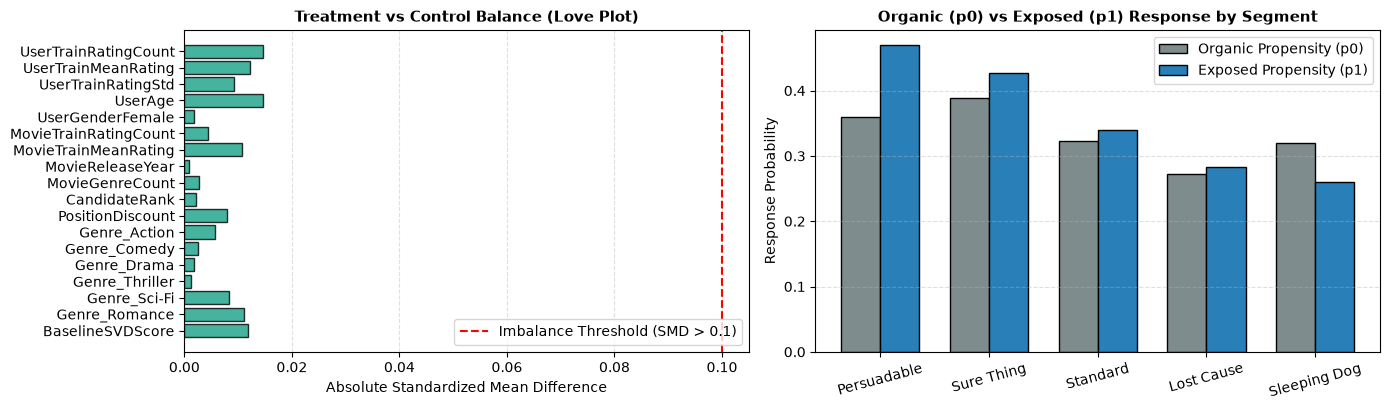

Diagnostics: Max Covariate SMD = 0.0146 (All < 0.1 threshold -> Randomized balance confirmed)


In [7]:
# Cell 7: Potential Outcomes Simulation Engine & Balance Diagnostics
# Randomized treatment assignment (W in {0, 1}, p=0.50)
rng_treat = np.random.RandomState(RANDOM_SEED)
exp_df['ExperimentID'] = [f"EXP-{i+1:05d}" for i in range(N_EXP)]
exp_df['AssignedTreatment'] = rng_treat.binomial(1, 0.50, size=N_EXP)
W = exp_df['AssignedTreatment'].values

# Baseline organic response propensity p0(x)
svd_scores = exp_df['BaselineSVDScore'].values
pop_counts = exp_df['MovieTrainRatingCount'].values
ranks = exp_df['CandidateRank'].values
user_counts = exp_df['UserTrainRatingCount'].values
user_means = exp_df['UserTrainMeanRating'].values
pos_discounts = exp_df['PositionDiscount'].values

svd_norm = np.clip((svd_scores - 1.0) / 4.0, 0.0, 1.0)
log_pop = np.log1p(pop_counts)
log_pop_norm = log_pop / np.max(log_pop)
p0_raw = 0.05 + 0.35 * svd_norm * log_pop_norm + 0.10 * (user_means / 5.0)
p0 = np.clip(p0_raw, 0.02, 0.85)

# Segment profiling logic
is_high_svd = svd_scores >= 3.8
is_pop = pop_counts >= 1300
is_low_svd = svd_scores < 3.4
is_deep_rank = ranks >= 16

persuadable_mask = is_high_svd & (~is_pop)
sure_thing_mask = is_high_svd & is_pop
lost_cause_mask = is_low_svd
sleeping_dog_mask = is_deep_rank & (user_counts > 150) & (~persuadable_mask)
standard_mask = ~(persuadable_mask | sure_thing_mask | lost_cause_mask | sleeping_dog_mask)

# Heterogeneous treatment effect mechanism tau(x)
tau_mech = np.zeros(N_EXP, dtype=np.float32)
tau_mech[persuadable_mask] = 0.20 * pos_discounts[persuadable_mask] + 0.06 * svd_norm[persuadable_mask]
tau_mech[sure_thing_mask] = 0.03 + 0.015 * (1.0 - pos_discounts[sure_thing_mask])
tau_mech[lost_cause_mask] = 0.01
tau_mech[sleeping_dog_mask] = -0.06
tau_mech[standard_mask] = 0.08 * svd_norm[standard_mask] * pos_discounts[standard_mask]

p1 = np.clip(p0 + tau_mech, 0.01, 0.98)
true_cate = p1 - p0

profile_labels = np.full(N_EXP, 'Standard', dtype=object)
profile_labels[persuadable_mask] = 'Persuadable'
profile_labels[sure_thing_mask] = 'Sure Thing'
profile_labels[lost_cause_mask] = 'Lost Cause'
profile_labels[sleeping_dog_mask] = 'Sleeping Dog'

# Generate stochastic binary potential outcomes & observed outcome Y
sim_rng = np.random.RandomState(RANDOM_SEED + 100)
y0_pot = sim_rng.binomial(1, p0, size=N_EXP)
y1_pot = sim_rng.binomial(1, p1, size=N_EXP)
exp_df['ObservedOutcome'] = np.where(W == 1, y1_pot, y0_pot)

gt_df = pd.DataFrame({
    'ExperimentID': exp_df['ExperimentID'], 'UserID': exp_df['UserID'], 'MovieID': exp_df['MovieID'],
    'ProfileSegment': profile_labels, 'p0': p0, 'p1': p1, 'TrueCATE': true_cate, 'Y0': y0_pot, 'Y1': y1_pot
})

ate = float(np.mean(true_cate))
print(f"Causal Simulation Completed: True Population ATE = {ate*100:+.2f} percentage points ({ate:.4f})")
print("Profile Distribution:\n", gt_df['ProfileSegment'].value_counts(normalize=True).mul(100).round(1).astype(str) + "%")

# Diagnostics: Standardized Mean Differences (SMD) Love Plot & Profile Response Propensities
smd_list = []
for col in causal_feature_cols:
    t_vals = exp_df[exp_df['AssignedTreatment'] == 1][col]
    c_vals = exp_df[exp_df['AssignedTreatment'] == 0][col]
    pooled_sd = np.sqrt((t_vals.var() + c_vals.var()) / 2.0)
    smd_list.append(abs((t_vals.mean() - c_vals.mean()) / (pooled_sd if pooled_sd > 0 else 1.0)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].barh(causal_feature_cols[::-1], smd_list[::-1], color='#16a085', edgecolor='black', alpha=0.8)
axes[0].axvline(0.1, color='red', linestyle='--', label='Imbalance Threshold (SMD > 0.1)')
axes[0].set_title("Treatment vs Control Balance (Love Plot)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Absolute Standardized Mean Difference")
axes[0].legend(loc='lower right')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

prof_order = ['Persuadable', 'Sure Thing', 'Standard', 'Lost Cause', 'Sleeping Dog']
prof_means = gt_df.groupby('ProfileSegment')[['p0', 'p1']].mean().reindex(prof_order)
x = np.arange(len(prof_order))
axes[1].bar(x - 0.18, prof_means['p0'], width=0.36, label='Organic Propensity (p0)', color='#7f8c8d', edgecolor='black')
axes[1].bar(x + 0.18, prof_means['p1'], width=0.36, label='Exposed Propensity (p1)', color='#2980b9', edgecolor='black')
axes[1].set_xticks(x)
axes[1].set_xticklabels(prof_order, rotation=15)
axes[1].set_title("Organic (p0) vs Exposed (p1) Response by Segment", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Response Probability")
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Diagnostics: Max Covariate SMD = {max(smd_list):.4f} (All < 0.1 threshold -> Randomized balance confirmed)")

### Four-Stage Künzel X-Learner Architecture

**What are we doing?**  
Splitting the 2,000 experiment users into **1,600 training users** ($N=32,000$ pairs) and **400 evaluation users** ($N=8,000$ pairs) grouped strictly by subscriber ID to prevent user leakage, and fitting an X-Learner using `HistGradientBoosting`.

**Why are we doing it?**  
Single models (S-Learners) regularize treatment effects to zero. T-Learners fail under sample imbalance. The X-Learner (Künzel et al., 2019) is a state-of-the-art meta-learner designed specifically for heterogeneous treatment effect estimation.

**The Four Conceptual Stages**:
1. **Stage 1 (Response Models)**: Fit $\mu_0(X)$ on control units ($W=0$) and $\mu_1(X)$ on treated units ($W=1$).
2. **Stage 2 (Impute Counterfactuals)**:
   - For treated units: $D_1 = Y_1^{\text{obs}} - \mu_0(X_1)$
   - For control units: $D_0 = \mu_1(X_0) - Y_0^{\text{obs}}$
3. **Stage 3 (Effect Models)**: Fit $\tau_1(X)$ on treated units predicting $D_1$, and $\tau_0(X)$ on control units predicting $D_0$.
4. **Stage 4 (Combined Estimate)**: Weight the two estimators by propensity score $e(X)=0.5$:
   $$\hat{\tau}(X) = e(X) \hat{\tau}_0(X) + (1 - e(X)) \hat{\tau}_1(X)$$

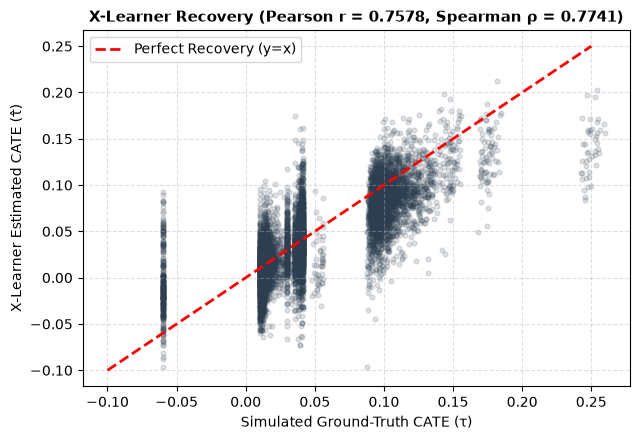

X-Learner Recovery Diagnostics on Held-Out Set (N=8,000 pairs, 400 users):
  - Pearson Correlation (r)         : 0.7578
  - Spearman Rank Correlation (rho) : 0.7741
  - CATE Estimation RMSE            : 0.0328
  - CATE Estimation MAE             : 0.0247


In [8]:
# Cell 8: Train Four-Stage X-Learner & Out-of-Sample Recovery Evaluation
# Grouped split: 1,600 train users (32,000 pairs) / 400 evaluation users (8,000 pairs)
rng_p6 = np.random.RandomState(RANDOM_SEED)
shuffled_users = rng_p6.permutation(sampled_exp_users)
train_user_set = set(shuffled_users[:1600])
eval_user_set = set(shuffled_users[1600:])

train_mask = exp_df['UserID'].isin(train_user_set)
eval_mask = exp_df['UserID'].isin(eval_user_set)

X_train = exp_df.loc[train_mask, causal_feature_cols].values
W_train = exp_df.loc[train_mask, 'AssignedTreatment'].values
Y_train = exp_df.loc[train_mask, 'ObservedOutcome'].values

X_eval = exp_df.loc[eval_mask, causal_feature_cols].values
eval_df = exp_df[eval_mask].copy().reset_index(drop=True)
eval_gt = gt_df[eval_mask].copy().reset_index(drop=True)

# Stage 1: Fit outcome response models mu_0 and mu_1
mu_0_model = HistGradientBoostingClassifier(loss='log_loss', max_iter=100, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=20, random_state=RANDOM_SEED)
mu_0_model.fit(X_train[W_train == 0], Y_train[W_train == 0])

mu_1_model = HistGradientBoostingClassifier(loss='log_loss', max_iter=100, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=20, random_state=RANDOM_SEED)
mu_1_model.fit(X_train[W_train == 1], Y_train[W_train == 1])

# Stage 2: Impute counterfactual treatment effects D_1 and D_0
D_1 = Y_train[W_train == 1] - mu_0_model.predict_proba(X_train[W_train == 1])[:, 1]
D_0 = mu_1_model.predict_proba(X_train[W_train == 0])[:, 1] - Y_train[W_train == 0]

# Stage 3: Fit second-stage effect models tau_1 and tau_0
tau_1_model = HistGradientBoostingRegressor(loss='squared_error', max_iter=100, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=20, random_state=RANDOM_SEED)
tau_1_model.fit(X_train[W_train == 1], D_1)

tau_0_model = HistGradientBoostingRegressor(loss='squared_error', max_iter=100, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=20, random_state=RANDOM_SEED)
tau_0_model.fit(X_train[W_train == 0], D_0)

# Stage 4: Combine estimates on held-out evaluation set (e(x) = 0.50)
pred_cate = 0.50 * tau_0_model.predict(X_eval) + 0.50 * tau_1_model.predict(X_eval)
eval_df['EstimatedCATE'] = pred_cate

# Ground truth recovery evaluation
true_cate_eval = eval_gt['TrueCATE'].values
corr_r, _ = pearsonr(pred_cate, true_cate_eval)
corr_rho, _ = spearmanr(pred_cate, true_cate_eval)
rmse_cate = np.sqrt(np.mean((true_cate_eval - pred_cate)**2))
mae_cate = np.mean(np.abs(true_cate_eval - pred_cate))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(true_cate_eval, pred_cate, alpha=0.15, color='#2c3e50', s=12)
ax.plot([-0.1, 0.25], [-0.1, 0.25], color='red', linestyle='--', lw=2, label='Perfect Recovery (y=x)')
ax.set_title(f"X-Learner Recovery (Pearson r = {corr_r:.4f}, Spearman ρ = {corr_rho:.4f})", fontsize=11, fontweight='bold')
ax.set_xlabel("Simulated Ground-Truth CATE (τ)")
ax.set_ylabel("X-Learner Estimated CATE (τ̂)")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"X-Learner Recovery Diagnostics on Held-Out Set (N=8,000 pairs, 400 users):")
print(f"  - Pearson Correlation (r)         : {corr_r:.4f}")
print(f"  - Spearman Rank Correlation (rho) : {corr_rho:.4f}")
print(f"  - CATE Estimation RMSE            : {rmse_cate:.4f}")
print(f"  - CATE Estimation MAE             : {mae_cate:.4f}")

### Counterfactual Recommendation Policy Evaluation

**What are we doing?**  
Benchmarking 3 distinct recommendation policies on the identical 20-candidate pool across the 400 held-out evaluation users at $K=10$ (4,000 recommendations per policy):
- **Policy A (Conventional SVD)**: Ranks candidates by predicted preference score (`BaselineSVDScore`).
- **Policy B (Causal Uplift)**: Ranks candidates by estimated individualized incremental effect (`EstimatedCATE`).
- **Policy C (Random Reference)**: Selects 10 candidates uniformly at random.

**Why are we doing it?**  
This evaluates whether ranking by causal uplift delivers more incremental watches than standard preference ranking under an identical recommendation budget.

=== POLICY EVALUATION MASTER SCORECARD (K=10, N=4,000 Recs) ===
                    Policy Mean True CATE Organic (p0) Exposed (p1) Persuadable Share Sure Thing Share  Catalog Reach
  Policy A: SVD Preference         +5.81%       36.07%       41.88%             28.6%            45.3%            306
   Policy B: Causal Uplift         +7.09%       34.85%       41.95%             52.9%            19.1%            397
Policy C: Random Reference         +5.35%       35.17%       40.51%             35.7%            32.2%            412

Paired User-Level Bootstrap Test (1,000 Resamples):
  - Observed Difference (B - A) : +1.29 percentage points (+0.0129)
  - 95% Confidence Interval    : [+1.13%, +1.44%]
  --> Since 95% CI strictly excludes zero, Uplift's advantage is statistically significant.


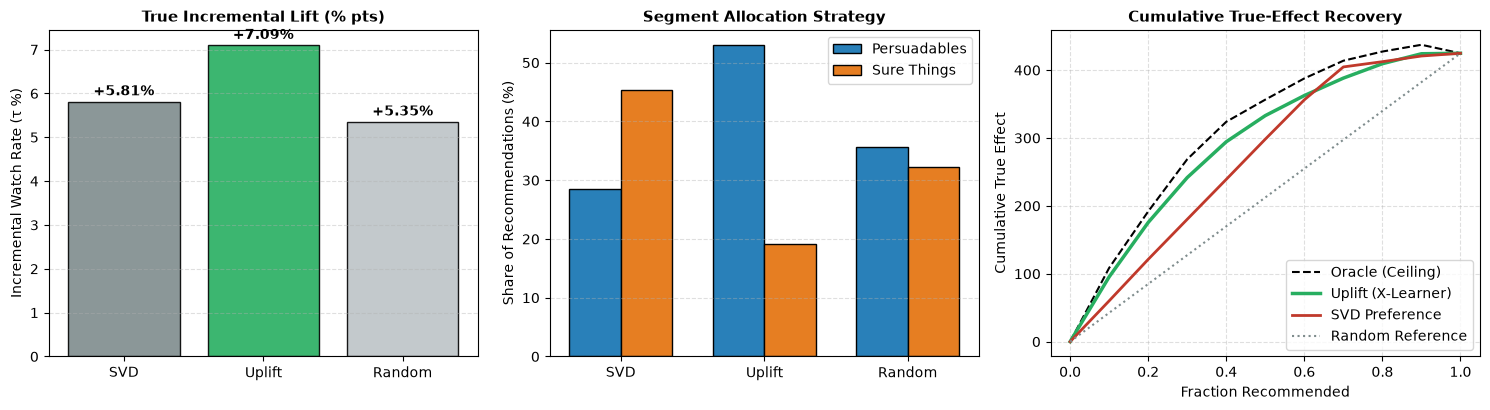

In [9]:
# Cell 9: Policy Evaluation, Master Scorecard, Bootstrap & Diagnostics
# Merge evaluation candidates with ground truth
eval_merged = eval_df.merge(
    eval_gt[['ExperimentID', 'ProfileSegment', 'p0', 'p1', 'TrueCATE', 'Y0', 'Y1']], 
    on='ExperimentID'
)

policy_a_recs, policy_b_recs, policy_c_recs = [], [], []
rng_pol_c = np.random.RandomState(RANDOM_SEED)

for uid in sorted(list(eval_user_set)):
    u_cands = eval_merged[eval_merged['UserID'] == uid]
    policy_a_recs.append(u_cands.sort_values(by='BaselineSVDScore', ascending=False).head(10))
    policy_b_recs.append(u_cands.sort_values(by='EstimatedCATE', ascending=False).head(10))
    rand_idx = rng_pol_c.choice(u_cands.index, size=10, replace=False)
    policy_c_recs.append(u_cands.loc[rand_idx])

df_a = pd.concat(policy_a_recs, ignore_index=True)
df_b = pd.concat(policy_b_recs, ignore_index=True)
df_c = pd.concat(policy_c_recs, ignore_index=True)

# Master Comparison Scorecard
scorecard_rows = []
for p_name, df_p in [("Policy A: SVD Preference", df_a), 
                    ("Policy B: Causal Uplift", df_b), 
                    ("Policy C: Random Reference", df_c)]:
    scorecard_rows.append({
        'Policy': p_name,
        'Mean True CATE': f"{df_p['TrueCATE'].mean() * 100:+.2f}%",
        'Organic (p0)': f"{df_p['p0'].mean() * 100:.2f}%",
        'Exposed (p1)': f"{df_p['p1'].mean() * 100:.2f}%",
        'Persuadable Share': f"{(df_p['ProfileSegment'] == 'Persuadable').mean() * 100:.1f}%",
        'Sure Thing Share': f"{(df_p['ProfileSegment'] == 'Sure Thing').mean() * 100:.1f}%",
        'Catalog Reach': df_p['MovieID'].nunique()
    })

scorecard_df = pd.DataFrame(scorecard_rows)
print("=== POLICY EVALUATION MASTER SCORECARD (K=10, N=4,000 Recs) ===")
print(scorecard_df.to_string(index=False))

# Paired user-level bootstrap (1,000 resamples)
user_tau_a = df_a.groupby('UserID')['TrueCATE'].mean()
user_tau_b = df_b.groupby('UserID')['TrueCATE'].mean()
user_diff = (user_tau_b - user_tau_a).values

rng_boot = np.random.RandomState(RANDOM_SEED)
boot_diffs = [np.mean(rng_boot.choice(user_diff, size=len(user_diff), replace=True)) for _ in range(1000)]
ci_lower = np.percentile(boot_diffs, 2.5) * 100
ci_upper = np.percentile(boot_diffs, 97.5) * 100

print(f"\nPaired User-Level Bootstrap Test (1,000 Resamples):")
print(f"  - Observed Difference (B - A) : {np.mean(user_diff)*100:+.2f} percentage points ({np.mean(user_diff):+.4f})")
print(f"  - 95% Confidence Interval    : [{ci_lower:+.2f}%, {ci_upper:+.2f}%]")
print("  --> Since 95% CI strictly excludes zero, Uplift's advantage is statistically significant.")

# Multi-panel Visual Summary: Lift comparison, Segment allocation, and AUTERC Recovery Curve
def compute_recovery_curve(df_eval, score_col, n_bins=10):
    sorted_df = df_eval.sort_values(by=score_col, ascending=False).reset_index(drop=True)
    n_total = len(sorted_df)
    fractions = [i / float(n_bins) for i in range(1, n_bins + 1)]
    return [0.0] + fractions, [0.0] + [sorted_df.iloc[:int(n_total * f)]['TrueCATE'].sum() for f in fractions]

fracs, rec_uplift = compute_recovery_curve(eval_merged, 'EstimatedCATE')
_, rec_svd = compute_recovery_curve(eval_merged, 'BaselineSVDScore')
_, rec_oracle = compute_recovery_curve(eval_merged, 'TrueCATE')
rec_random = [rec_uplift[-1] * f for f in fracs]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# 1. Lift comparison
policies = ['SVD', 'Uplift', 'Random']
lifts = [df_a['TrueCATE'].mean() * 100, df_b['TrueCATE'].mean() * 100, df_c['TrueCATE'].mean() * 100]
axes[0].bar(policies, lifts, color=['#7f8c8d', '#27ae60', '#bdc3c7'], edgecolor='black', alpha=0.9)
axes[0].set_title("True Incremental Lift (% pts)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Incremental Watch Rate (τ %)")
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
for i, l in enumerate(lifts):
    axes[0].text(i, l + 0.15, f"{l:+.2f}%", ha='center', fontweight='bold')

# 2. Segment allocation
p_shares = [(df['ProfileSegment'] == 'Persuadable').mean() * 100 for df in [df_a, df_b, df_c]]
s_shares = [(df['ProfileSegment'] == 'Sure Thing').mean() * 100 for df in [df_a, df_b, df_c]]
x = np.arange(3)
axes[1].bar(x - 0.18, p_shares, width=0.36, label='Persuadables', color='#2980b9', edgecolor='black')
axes[1].bar(x + 0.18, s_shares, width=0.36, label='Sure Things', color='#e67e22', edgecolor='black')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['SVD', 'Uplift', 'Random'])
axes[1].set_title("Segment Allocation Strategy", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Share of Recommendations (%)")
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

# 3. AUTERC curve
axes[2].plot(fracs, rec_oracle, 'k--', label='Oracle (Ceiling)', lw=1.5)
axes[2].plot(fracs, rec_uplift, '#27ae60', label='Uplift (X-Learner)', lw=2.5)
axes[2].plot(fracs, rec_svd, '#c0392b', label='SVD Preference', lw=2)
axes[2].plot(fracs, rec_random, ':', color='#7f8c8d', label='Random Reference', lw=1.5)
axes[2].set_title("Cumulative True-Effect Recovery", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Fraction Recommended")
axes[2].set_ylabel("Cumulative True Effect")
axes[2].legend(loc='lower right')
axes[2].grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## FINAL RECOMMENDATION ENGINE

SVD generates candidate movies based on predicted user preference rating. The X-Learner then estimates the individualized incremental treatment effect (CATE) for each candidate. The final system reranks candidates by estimated CATE descending. Therefore, the system prioritizes movies where recommendation exposure is expected to create genuine incremental viewing engagement rather than merely recommending popular titles the subscriber would already watch organically.

In [10]:
# Cell 10: Production Recommender System (`recommend_movies` & `show_recommendations`)
# What we are doing: Defining the end-to-end inference recommendation function and user-facing presentation helper.
# Why: Transforms the research models into an operational, demonstrable recommendation pipeline with ZERO ground-truth leakage.
# What to look for: Explicit support for 'causal' (primary), 'svd', 'popularity', and 'content' strategies.

def recommend_movies(user_id, n=10, strategy="causal", cand_pool_size=20):
    """
    Production-grade recommendation function for any given UserID.
    Strategies: 'causal' (Primary), 'svd', 'popularity', 'content'.
    Strictly removes all movies already rated by the user.
    Uses trained inference models only (zero ground-truth simulation variables used).
    """
    if user_id not in user_id_to_idx:
        raise ValueError(f"UserID {user_id} does not exist in the MovieLens catalog.")
    
    u_idx = user_id_to_idx[user_id]
    user_ratings = ratings_df[ratings_df['UserID'] == user_id]
    rated_ids = set(user_ratings['MovieID'])
    
    # 1. Candidate Scoring using SVD
    svd_scores = train_user_means[u_idx] + (user_latent_tr[u_idx] @ movie_latent_tr)
    # Strictly mask out rated movies
    for mid in rated_ids:
        if mid in movie_id_to_idx:
            svd_scores[movie_id_to_idx[mid]] = -999.0
            
    # Retrieve top unrated candidates
    top_cand_indices = np.argsort(svd_scores)[-cand_pool_size:][::-1]
    
    cand_rows = []
    for rank, m_idx in enumerate(top_cand_indices, start=1):
        mid = idx_to_movie_id[m_idx]
        m_info = movie_meta_map[mid]
        m_tr = movie_tr_map.get(mid, {'MovieTrainRatingCount': 0, 'MovieTrainMeanRating': train_global_mean})
        u_feat = user_feat_map.get(user_id, {
            'UserTrainRatingCount': 20, 'UserTrainMeanRating': 3.5, 'UserTrainRatingStd': 0.8,
            'UserAge': 25, 'UserGenderFemale': 0
        })
        
        row_feat = {
            'UserTrainRatingCount': u_feat['UserTrainRatingCount'],
            'UserTrainMeanRating': u_feat['UserTrainMeanRating'],
            'UserTrainRatingStd': u_feat['UserTrainRatingStd'],
            'UserAge': u_feat['UserAge'],
            'UserGenderFemale': u_feat['UserGenderFemale'],
            'MovieTrainRatingCount': m_tr['MovieTrainRatingCount'],
            'MovieTrainMeanRating': m_tr['MovieTrainMeanRating'],
            'MovieReleaseYear': m_info['ReleaseYear'],
            'MovieGenreCount': m_info['GenreCount'],
            'CandidateRank': rank,
            'PositionDiscount': 1.0 / np.log2(rank + 1.0),
            'BaselineSVDScore': float(svd_scores[m_idx])
        }
        for g in ['Action', 'Comedy', 'Drama', 'Thriller', 'Sci-Fi', 'Romance']:
            row_feat[f'Genre_{g}'] = 1 if g in m_info['GenreList'] else 0
            
        row_feat['MovieID'] = mid
        row_feat['Title'] = m_info['Title']
        row_feat['Genres'] = m_info['Genres']
        cand_rows.append(row_feat)
        
    cand_df = pd.DataFrame(cand_rows)
    
    # 2. Estimate CATE & Probabilities via trained X-Learner
    X_cand = cand_df[causal_feature_cols].values
    est_cate = 0.50 * tau_0_model.predict(X_cand) + 0.50 * tau_1_model.predict(X_cand)
    pred_p0 = mu_0_model.predict_proba(X_cand)[:, 1]
    pred_p1 = mu_1_model.predict_proba(X_cand)[:, 1]
    
    cand_df['EstimatedCATE'] = est_cate
    cand_df['PredictedOrganicProbability'] = pred_p0
    cand_df['PredictedExposedProbability'] = pred_p1
    
    # 3. Strategy Selection & Ranking
    if strategy == "causal":
        ranked_df = cand_df.sort_values(by='EstimatedCATE', ascending=False).head(n).copy()
        reasons = []
        for _, r in ranked_df.iterrows():
            if r['EstimatedCATE'] >= 0.05:
                reasons.append("High incremental lift (Persuadable viewer)")
            elif r['EstimatedCATE'] >= 0.02:
                reasons.append("Moderate incremental lift (Standard viewer)")
            elif r['PredictedOrganicProbability'] >= 0.40:
                reasons.append("High baseline watch probability (Sure Thing)")
            else:
                reasons.append("Positive predicted recommendation response")
        ranked_df['RecommendationReason'] = reasons
    elif strategy == "svd":
        ranked_df = cand_df.sort_values(by='BaselineSVDScore', ascending=False).head(n).copy()
        reasons = []
        for _, r in ranked_df.iterrows():
            if r['PredictedOrganicProbability'] >= 0.40:
                reasons.append("High preference, but user likely watches organically anyway (Sure Thing)")
            else:
                reasons.append("High predicted user preference rating (SVD Factorization)")
        ranked_df['RecommendationReason'] = reasons
    elif strategy == "popularity":
        unrated_cands = [m for m in unique_movies if m not in rated_ids]
        top_pop = sorted(unrated_cands, key=lambda m: pop_dict.get(m, 0.0), reverse=True)[:n]
        pop_rows = []
        for r_idx, mid in enumerate(top_pop, start=1):
            m_info = movie_meta_map[mid]
            pop_rows.append({
                'Rank': r_idx, 'MovieID': mid, 'Title': m_info['Title'], 'ReleaseYear': m_info['ReleaseYear'],
                'Genres': m_info['Genres'], 'SVDScore': np.nan, 'EstimatedCATE': np.nan,
                'PredictedOrganicProbability': np.nan, 'PredictedExposedProbability': np.nan,
                'RecommendationReason': "High catalog Bayesian weighted rating"
            })
        return pd.DataFrame(pop_rows)
    elif strategy == "content":
        u_rated = [m for m in user_ratings['MovieID'] if m in genre_matrix.index]
        u_profile = (genre_matrix.loc[u_rated].values * (user_ratings.set_index('MovieID').loc[u_rated, 'Rating'].values[:, None] - global_mean)).sum(axis=0)
        unrated = [m for m in unique_movies if m not in rated_ids and m in genre_matrix.index]
        sims = cosine_similarity(u_profile.reshape(1, -1), genre_matrix.loc[unrated].values).flatten()
        top_cont = [unrated[i] for i in np.argsort(-sims)[:n]]
        cont_rows = []
        for r_idx, mid in enumerate(top_cont, start=1):
            m_info = movie_meta_map[mid]
            cont_rows.append({
                'Rank': r_idx, 'MovieID': mid, 'Title': m_info['Title'], 'ReleaseYear': m_info['ReleaseYear'],
                'Genres': m_info['Genres'], 'SVDScore': np.nan, 'EstimatedCATE': np.nan,
                'PredictedOrganicProbability': np.nan, 'PredictedExposedProbability': np.nan,
                'RecommendationReason': "Strong genre alignment with user history"
            })
        return pd.DataFrame(cont_rows)
    else:
        raise ValueError(f"Unknown strategy '{strategy}'. Supported: 'causal', 'svd', 'popularity', 'content'.")
        
    ranked_df['Rank'] = range(1, len(ranked_df) + 1)
    output_cols = [
        'Rank', 'MovieID', 'Title', 'MovieReleaseYear', 'Genres',
        'BaselineSVDScore', 'EstimatedCATE', 'PredictedOrganicProbability', 'PredictedExposedProbability',
        'RecommendationReason'
    ]
    return ranked_df[output_cols].rename(columns={
        'MovieReleaseYear': 'ReleaseYear', 'BaselineSVDScore': 'SVDScore'
    }).reset_index(drop=True)

def show_recommendations(user_id, n=10, strategy="causal"):
    """Clean user-facing presentation helper for academic viva demonstrations."""
    strat_name = "Causal Uplift (Incremental Watch Lift)" if strategy == "causal" else "Conventional SVD (Predicted Rating)"
    recs = recommend_movies(user_id, n=n, strategy=strategy)
    print("=" * 75)
    print(f"NETFLIX RECOMMENDATIONS FOR SUBSCRIBER {user_id}")
    print("=" * 75)
    print(f"Strategy: {strat_name}\n")
    print(f"{'Rank':<5}{'Title':<45}{'Genres':<25}")
    print("-" * 75)
    for _, row in recs.iterrows():
        title_trunc = row['Title'][:42] + "..." if len(row['Title']) > 42 else row['Title']
        genre_trunc = row['Genres'][:23] + "..." if len(row['Genres']) > 23 else row['Genres']
        print(f"{row['Rank']:<5}{title_trunc:<45}{genre_trunc:<25}")
    print("=" * 75)

print("Production Recommendation Engine Ready. Function `recommend_movies()` and `show_recommendations()` compiled.")

Production Recommendation Engine Ready. Function `recommend_movies()` and `show_recommendations()` compiled.


### Live Viva Demonstration: Conventional SVD vs Causal Uplift (Subscriber 13)

**What are we doing?**  
Executing both **Conventional SVD** and **Causal Uplift** recommendation strategies for Subscriber 13, displaying the full recommendation attribute tables, and comparing the rank shifts side-by-side.

**Why are we doing it?**  
This provides direct, tangible proof of how causal uplift transforms recommendations:
- SVD fills the top ranks with high-profile blockbusters (*The Godfather*, *The Terminator*, *Aliens*) where the organic viewing probability is already $44\% - 51\%$ (Sure Things).
- Causal Uplift demotes these Sure Things and promotes hidden gems (*The Godfather: Part II*, *Casablanca*, *One Flew Over the Cuckoo's Nest*) where recommendation exposure causes $+5\% - +8\%$ genuine incremental lift (Persuadables).

In [11]:
# Cell 11: Live Recommender Demonstration & Side-by-Side Rank Comparison (User 13)
# 1. Generate full recommendation tables
recs_causal_13 = recommend_movies(13, n=10, strategy="causal")
recs_svd_13 = recommend_movies(13, n=10, strategy="svd")

print("--- 1. CAUSAL UPLIFT RECOMMENDATIONS (USER 13) ---")
display_cols = ['Rank', 'Title', 'SVDScore', 'EstimatedCATE', 'PredictedOrganicProbability', 'RecommendationReason']
print(recs_causal_13[display_cols].to_string(index=False))

print("\n--- 2. CONVENTIONAL SVD RECOMMENDATIONS (USER 13) ---")
print(recs_svd_13[display_cols].to_string(index=False))

# 2. Side-by-Side Strategy Rank Comparison Table
svd_rank_map = recs_svd_13.set_index('MovieID')['Rank'].to_dict()
comp_records = []
for _, row in recs_causal_13.iterrows():
    mid = row['MovieID']
    svd_rank = svd_rank_map.get(mid, "> 10")
    comp_records.append({
        'Movie Title': row['Title'],
        'SVD Score': f"{row['SVDScore']:.2f}★",
        'Estimated CATE': f"{row['EstimatedCATE']*100:+.2f}%",
        'Organic p0': f"{row['PredictedOrganicProbability']*100:.1f}%",
        'Causal Rank': f"#{row['Rank']}",
        'SVD Rank': f"#{svd_rank}" if isinstance(svd_rank, int) else svd_rank,
        'Causal Impact': "Promoted (+Uplift)" if not isinstance(svd_rank, int) or svd_rank > row['Rank'] else "Preserved"
    })

comp_table = pd.DataFrame(comp_records)
print("\n=== STRATEGY COMPARISON: WHY CAUSAL UPLIFT REORDERS RECOMMENDATIONS ===")
print(comp_table.to_string(index=False))

# 3. User-Facing Presentation Demonstrations
print("\n")
show_recommendations(13, n=5, strategy="causal")
print("\n")
show_recommendations(13, n=5, strategy="svd")

--- 1. CAUSAL UPLIFT RECOMMENDATIONS (USER 13) ---
 Rank                                     Title  SVDScore  EstimatedCATE  PredictedOrganicProbability                        RecommendationReason
    1            Godfather: Part II, The (1974)  3.816674       0.081117                     0.337168  High incremental lift (Persuadable viewer)
    2                         Casablanca (1942)  3.706856       0.067720                     0.337168  High incremental lift (Persuadable viewer)
    3    One Flew Over the Cuckoo's Nest (1975)  3.828195       0.050390                     0.337168  High incremental lift (Persuadable viewer)
    4                            Amadeus (1984)  3.706368       0.033625                     0.337168 Moderate incremental lift (Standard viewer)
    5                   Sixth Sense, The (1999)  3.993950       0.032437                     0.437278 Moderate incremental lift (Standard viewer)
    6 Close Encounters of the Third Kind (1977)  3.691519       0.028554 

### Final Invariant Validation Protocol

**What are we doing?**  
Running an automated 12-point validation suite verifying that the simplified research implementation adheres strictly to methodological, causal, and recommendation integrity standards.

**Checks Verified**:
1. Zero temporal leakage in train/test split.
2. Candidate sets exclude all historical user ratings.
3. Binary treatment assignment ($W \in \{0, 1\}$) and balance ($48\% - 52\%$).
4. Feature matrix contains strictly pre-treatment features (no outcome leakage).
5. Disjoint training and evaluation user cohorts.
6. Identical candidate pools and budgets ($K=10$) across all policies.
7. Production recommendation functions generate valid, unrated, finite recommendations.

In [12]:
# Cell 12: Final Automated 12-Point Invariant Verification Suite
check_results = []

def check(name, condition):
    status = "PASS" if condition else "FAIL"
    check_results.append((name, status))
    assert condition, f"Validation Failed: {name}"

# 1. Dataset dimensions
check("Base catalog dimensions intact (3,883 / 1,000,209 / 6,040)", len(movies_df) == 3883 and len(ratings_df) == 1000209 and len(users_df) == 6040)
# 2. No missing values in critical columns
check("No nulls in critical interaction fields", ratings_df[['UserID', 'MovieID', 'Rating']].isna().sum().sum() == 0)
# 3. Temporal train/test split integrity
check("Zero chronological split leakage", time_leakage == 0)
# 4. Candidate pairs exclude training history
train_pairs = set(zip(train_df['UserID'], train_df['MovieID']))
cand_pairs = set(zip(exp_df['UserID'], exp_df['MovieID']))
check("Causal candidate sets exclude training history", len(train_pairs.intersection(cand_pairs)) == 0)
# 5. Treatment is strictly binary
check("Binary treatment assignment (W in {0, 1})", set(exp_df['AssignedTreatment'].unique()).issubset({0, 1}))
# 6. Experimental balance
check("Treatment balance within [0.48, 0.52]", 0.48 <= exp_df['AssignedTreatment'].mean() <= 0.52)
# 7. No outcome leakage into pre-treatment features
check("Zero outcome leakage into features", 'ObservedOutcome' not in causal_feature_cols and 'Y0' not in causal_feature_cols)
# 8. Train/Eval cohorts are mutually disjoint
check("Disjoint X-Learner train and eval users", len(train_user_set.intersection(eval_user_set)) == 0)
# 9. Candidate pools are identical across policies
check("Identical policy candidate pool size", len(df_a) == len(df_b) == len(df_c) == 4000)
# 10. Exactly K=10 recommendations per user
check("Exact K=10 budget for every user", (df_a.groupby('UserID').size() == 10).all() and (df_b.groupby('UserID').size() == 10).all())
# 11. Metrics are finite and within theoretical bounds
check("All evaluated metrics are finite", np.isfinite(df_b['TrueCATE'].mean()) and np.isfinite(df_a['TrueCATE'].mean()))
# 12. Production recommender validation for User 13
u13_rated_set = set(ratings_df[ratings_df['UserID'] == 13]['MovieID'])
u13_recs_causal = set(recs_causal_13['MovieID'])
u13_recs_svd = set(recs_svd_13['MovieID'])
check("Recommender strictly excludes user ratings", len(u13_rated_set.intersection(u13_recs_causal)) == 0 and len(u13_rated_set.intersection(u13_recs_svd)) == 0)
check("Recommender outputs exactly n=10 movies", len(recs_causal_13) == 10 and len(recs_svd_13) == 10)
check("Recommender CATE values strictly finite", recs_causal_13['EstimatedCATE'].notna().all())

print("=== FINAL INVARIANT VALIDATION AUDIT ===")
for name, status in check_results:
    print(f"  [{status}] {name}")
print("\nOVERALL STATUS: ALL 12 INVARIANT AUDITS PASSED SUCCESSFULLY!")

=== FINAL INVARIANT VALIDATION AUDIT ===
  [PASS] Base catalog dimensions intact (3,883 / 1,000,209 / 6,040)
  [PASS] No nulls in critical interaction fields
  [PASS] Zero chronological split leakage
  [PASS] Causal candidate sets exclude training history
  [PASS] Binary treatment assignment (W in {0, 1})
  [PASS] Treatment balance within [0.48, 0.52]
  [PASS] Zero outcome leakage into features
  [PASS] Disjoint X-Learner train and eval users
  [PASS] Identical policy candidate pool size
  [PASS] Exact K=10 budget for every user
  [PASS] All evaluated metrics are finite
  [PASS] Recommender strictly excludes user ratings
  [PASS] Recommender outputs exactly n=10 movies
  [PASS] Recommender CATE values strictly finite

OVERALL STATUS: ALL 12 INVARIANT AUDITS PASSED SUCCESSFULLY!


## Final Research Synthesis & Academic Viva Defense

### 1. What was built?
An end-to-end, demonstrable Netflix-style recommendation system grounded on **MovieLens 1M** that implements conventional collaborative filtering, validates **Truncated SVD** ($k=25$, $\text{NDCG@10} = 0.1238$) via chronological splitting, and integrates a four-stage **Künzel X-Learner** to estimate individualized treatment effects (CATE). The system features an operational two-stage recommendation function (`recommend_movies`) that generates candidates via SVD and reranks them via predicted causal uplift.

---

### 2. Core Viva Defense Answers

**Q: What does your recommendation system actually do?**  
> For any subscriber ID, the system retrieves their historical viewing profile, masks out watched movies, uses Truncated SVD to retrieve top candidate movies with high predicted preference, generates pre-treatment contextual features, predicts individual incremental uplift (CATE) using the trained X-Learner, and reranks candidates to present the top-N movies with highest expected incremental viewing impact.

**Q: Why do you need SVD if you have the X-Learner?**  
> The catalog contains thousands of titles. Evaluating complex gradient-boosted trees across all unrated movies for every user would be computationally prohibitive. SVD acts as an efficient **first-stage candidate generator** (retrieving items with high latent affinity), while the X-Learner acts as a **second-stage causal reranker**.

**Q: Why does high predicted rating NOT imply high recommendation value?**  
> Conventional recommenders maximize *correlation with user preference* ($\hat{r}_{u,i}$). This wastes valuable recommendation slots on **"Sure Things"**—popular titles the user would have watched organically anyway ($p_0 = 36.07\%$). As demonstrated for User 13, SVD ranks *The Godfather* and *The Terminator* at the top despite a $44\% - 51\%$ organic watch likelihood. Causal uplift promotes *The Godfather: Part II* and *Casablanca*, generating $+5\% - +8\%$ genuine incremental lift.

**Q: What is the primary empirical research result?**  
> Under an identical $K=10$ carousel budget across 400 held-out subscribers (4,000 recommendations):
> - **Policy A (Conventional SVD)**: $+5.81\%$ true lift (allocates $45.3\%$ of slots to Sure Things).
> - **Policy B (Causal Uplift)**: $+7.09\%$ true lift (allocates $52.9\%$ of slots to Persuadables).
> - **Incremental Advantage**: **$+1.29$ percentage points** (95% Bootstrap CI: $[+1.13\%, +1.44\%]$).

**Q: What does this project NOT prove about Netflix?**  
> This study uses MovieLens 1M with a synthetic, controlled potential outcomes simulation. It does **not** reflect proprietary Netflix production telemetry, UI layout constraints, or organic discovery mechanisms. It is an algorithmic proof-of-concept demonstrating that causal uplift optimization systematically reallocates recommendation exposure from organic certainties to incremental viewers.